In [1]:
import os
from glob import glob

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import sys

print("Python executable:", sys.executable)
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Python executable: c:\Users\Admin\Desktop\iitb_fellowship\venv\Scripts\python.exe
Torch version: 2.7.1+cu118
CUDA available: True
GPU: NVIDIA RTX 4500 Ada Generation


In [2]:
RAW_DIR = "../data/raw/PlantVillage"
PROCESSED_DIR = "../data/processed/PlantVillage"

os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Raw dir exists:", os.path.exists(RAW_DIR))
print("Processed dir:", PROCESSED_DIR)


Raw dir exists: True
Processed dir: ../data/processed/PlantVillage


In [3]:
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png")

classes = sorted([
    d for d in os.listdir(RAW_DIR)
    if os.path.isdir(os.path.join(RAW_DIR, d))
])

print("Classes found:")
for cls in classes:
    images = [
        f for f in os.listdir(os.path.join(RAW_DIR, cls))
        if f.lower().endswith(VALID_EXTENSIONS)
    ]
    print(f"{cls}: {len(images)} images")


Classes found:
Pepper__bell___Bacterial_spot: 997 images
Pepper__bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_Late_blight: 1909 images
Tomato_Leaf_Mold: 952 images
Tomato_Septoria_leaf_spot: 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
Tomato__Target_Spot: 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
Tomato__Tomato_mosaic_virus: 373 images
Tomato_healthy: 1591 images


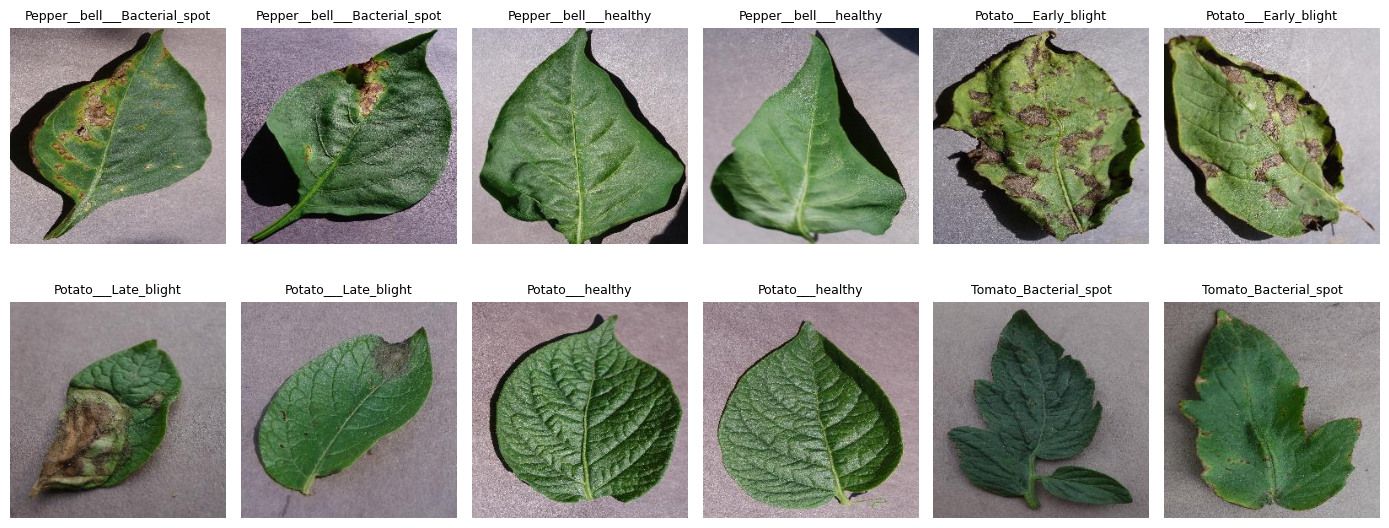

In [4]:
sample_paths = []

for cls in classes[:6]:  # show only first 6 classes
    imgs = [
        os.path.join(RAW_DIR, cls, f)
        for f in os.listdir(os.path.join(RAW_DIR, cls))
        if f.lower().endswith(VALID_EXTENSIONS)
    ]
    sample_paths += imgs[:2]

plt.figure(figsize=(14, 6))

for i, img_path in enumerate(sample_paths):
    img = cv2.imread(img_path)
    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 6, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(os.path.dirname(img_path)), fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()
